In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

MODEL_SEED = 3312605 # obtained from running allocation code

In [2]:
df = pd.read_csv("../data/allocated/student_restaurants_3312605.csv")
df

,record_id,title,subzone,cuisine,type,cost,lat,lng,coordinate_quality,rating_number_historical
0,9e6e1962c5889e46,Lid & Jar,Rhodes,"[""Modern Australian"", ""Cafe""]","[""Café""]",45.0,-33.831843,151.086170,within_screening_box,3.4
1,31fbcdd01c3ce028,Billy's Kitchen at Botany Golf Club,Botany Bay,"[""Asian"", ""Bar Food""]","[""Casual Dining"", ""Bar""]",50.0,-33.958560,151.207672,within_screening_box,3.2
2,9d70f4c9b5fc9455,JB's on Canterbury,Dulwich Hill,"[""Salad"", ""Sandwich"", ""Burger"", ""Coffee and Tea""]","[""Café""]",40.0,-33.904198,151.141386,within_screening_box,2.7
3,37813654843a9df3,Sienna Cafe,Surry Hills,"[""Cafe""]","[""Café""]",25.0,-33.885416,151.207945,within_screening_box,NaN
4,a6637650ab9821e1,Flame 'n' Chicken,Brookvale,"[""Burger"", ""Fast Food""]","[""Food Court""]",35.0,-33.756605,151.281530,within_screening_box,NaN
...,...,...,...,...,...,...,...,...,...,...
2995,d84143321f9e1ddf,Golden Rose Chinese Restaurant,Moorebank,"[""Chinese""]","[""Casual Dining""]",40.0,-33.932906,150.949682,within_screening_box,3.2
2996,fc44981f694cbd68,Local Bean @ Knightsbridge,"Knightsbridge Shopping Centre, The Hills","[""Cafe""]","[""Café""]",40.0,-33.713075,150.994107,within_screening_box,2.5
2997,79a3b3a2b867733a,Cucinetta,Hunters Hill,"[""Italian""]","[""Casual Dining""]",100.0,-33.840597,151.170828,within_screening_box,3.5
2998,92b2c3537b0ede00,Rosé Royale,Potts Point,"[""Bar Food"", ""French""]","[""Wine Bar""]",70.0,-33.874474,151.224052,within_screening_box,3.1


In [3]:
# Clean cuisine and type first
df['cuisine'] = df['cuisine'].str.strip("[] ").str.replace('"', "").str.replace(' ', "")
df['type'] = df['type'].str.strip("[] ").str.replace('"', "").str.replace(' ', "")

In [4]:
# Task A1
# Check row and columns, data tyles, missing values
print(f"Row count: {len(df)}")
print(f"Columns: {df.columns.tolist()}")
print("\nData Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())

Row count: 3000
Columns: ['record_id', 'title', 'subzone', 'cuisine', 'type', 'cost', 'lat', 'lng', 'coordinate_quality', 'rating_number_historical']

Data Types:
record_id                       str
title                           str
subzone                         str
cuisine                         str
type                            str
cost                        float64
lat                         float64
lng                         float64
coordinate_quality              str
rating_number_historical    float64
dtype: object

Missing Values:
record_id                     0
title                         0
subzone                       0
cuisine                       0
type                          8
cost                        115
lat                          97
lng                          97
coordinate_quality            0
rating_number_historical    947
dtype: int64


In [5]:
# Check rating bands
missing_rating = df['rating_number_historical'].isna().sum()
below_2_5 = (df['rating_number_historical'] < 2.5).sum()
band_2_5_to_3_4 = ((df['rating_number_historical'] >= 2.5) & (df['rating_number_historical'] <= 3.4)).sum()
band_3_5_to_3_9 = ((df['rating_number_historical'] >= 3.5) & (df['rating_number_historical'] <= 3.9)).sum()
band_4_0_to_4_4 = ((df['rating_number_historical'] >= 4.0) & (df['rating_number_historical'] <= 4.4)).sum()
above_4_5 = (df['rating_number_historical'] >= 4.5).sum()

print(f"Below 2.5: {below_2_5}")
print(f"2.5-3.4: {band_2_5_to_3_4}")
print(f"3.5-3.9: {band_3_5_to_3_9}")
print(f"4.0-4.4: {band_4_0_to_4_4}")
print(f"4.5+: {above_4_5}")
print(f"No rating: {missing_rating}")

Below 2.5: 60
2.5-3.4: 1286
3.5-3.9: 547
4.0-4.4: 145
4.5+: 15
No rating: 947


In [6]:
# Check duplicates
duplicates = df['title'].value_counts()
duplicates = duplicates[duplicates > 1]
print(f"Restaurants listed more than once: {len(duplicates)}")

Restaurants listed more than once: 8


In [7]:
duplicates

title
Annie's Bakery        2
The Garden            2
Cafe Piccolo          2
Golden Sands          2
Queens Park Pizza     2
The Chocolate Room    2
Royal Hotel           2
Fusion Cafe           2
Name: count, dtype: int64

In [8]:
# Summary stats
print(df.describe(include='all').to_string())

               record_id           title subzone cuisine          type         cost          lat          lng    coordinate_quality  rating_number_historical
count               3000            3000    3000    3000          2992  2885.000000  2903.000000  2903.000000                  3000               2053.000000
unique              3000            2992     447     778            49          NaN          NaN          NaN                     3                       NaN
top     9e6e1962c5889e46  Annie's Bakery     CBD    Cafe  CasualDining          NaN          NaN          NaN  within_screening_box                       NaN
freq                   1               2     135     489          1403          NaN          NaN          NaN                  2903                       NaN
mean                 NaN             NaN     NaN     NaN           NaN    51.720624   -33.861624   151.120730                   NaN                  3.276473
std                  NaN             NaN     NaN    

In [9]:
# A1: check coordinates
import geopandas as gpd
from shapely.geometry import Point

# Load GeoJSON data
geo_syd = gpd.read_file("../data/raw/sydney.geojson")

# drop suburbs without polygon features - for A3
geo_syd = geo_syd[~geo_syd['geometry'].isna()]

# delete rows in df without lat and long
df_valid = df.dropna(subset=['lat', 'lng']).copy()

# clean names (lowercase and remove ' (NSW)' suffixes)
df_valid['subzone_clean'] = df_valid['subzone'].astype(str).str.strip().str.lower()
geo_syd['SSC_NAME_clean'] = geo_syd['SSC_NAME'].astype(str).str.replace(' (NSW)', '', regex=False).str.strip().str.lower()

# convert csv coordinates into geometric points
geometry = [Point(xy) for xy in zip(df_valid['lng'], df_valid['lat'])]
geo_restaurants = gpd.GeoDataFrame(df_valid, geometry=geometry, crs=geo_syd.crs)

# spatial join, checks which polygon each point falls into
# left join to preserve all restaurants
joined = gpd.sjoin(geo_restaurants, geo_syd, how="left", predicate="intersects")

# Points outside the map (no matching index)
outside_map = joined[joined['index_right'].isna()]

# Points inside the map, but subzone doesn't match GeoJSON SSC_NAME
inside_map = joined[~joined['index_right'].isna()]
mismatches = inside_map[inside_map['subzone_clean'] != inside_map['SSC_NAME_clean']]

print(f"Points outside the map: {len(outside_map)}")
print(f"Points with mismatched subzones: {len(mismatches)}")

Points outside the map: 291
Points with mismatched subzones: 918


Unique cuisine labels count: 114


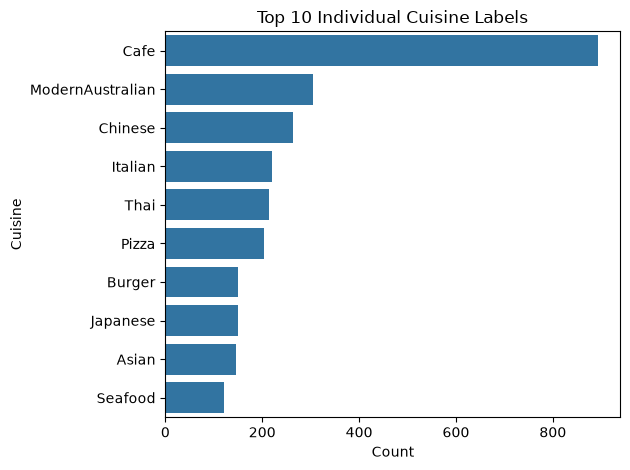

In [10]:
# Q1: How many different cuisine labels are there?

cuisines_list = []
for c_str in df['cuisine']:
    c_str_list = c_str.split(",")
    cuisines_list.extend(c_str_list)

print(f"Unique cuisine labels count: {len(set(cuisines_list))}")

plt.figure()
cuisine_counts = pd.Series(cuisines_list).value_counts().head(10)
sns.barplot(x=cuisine_counts.values, y=cuisine_counts.index)
plt.title("Top 10 Individual Cuisine Labels")
plt.xlabel("Count")
plt.ylabel("Cuisine")
plt.tight_layout()
plt.show()

Top 3 subzones:
subzone
CBD            135
Surry Hills     73
Parramatta      65
Name: count, dtype: int64


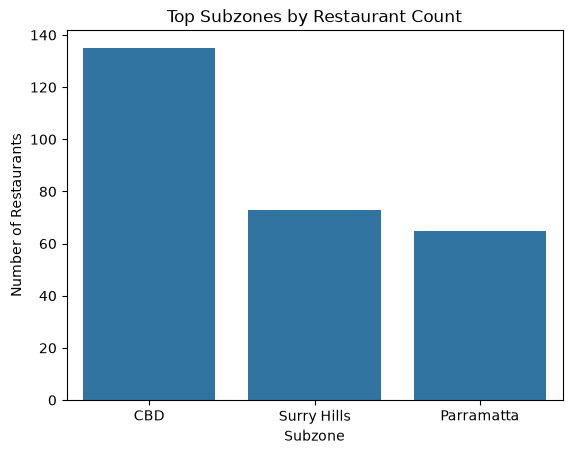

In [11]:
# Q2: Which 3 subzone labels have the most restaurants?
top_subzones = df['subzone'].value_counts().head(3)
print("Top 3 subzones:")
print(top_subzones)

plt.figure()
top_sub_counts = df['subzone'].value_counts().head(3)
sns.barplot(x=top_sub_counts.index, y=top_sub_counts.values)
plt.title("Top Subzones by Restaurant Count")
plt.xlabel("Subzone")
plt.ylabel("Number of Restaurants")
plt.show()

Top band count: 15, mean cost: 126.33
Bottom band count: 60, mean cost: 57.23


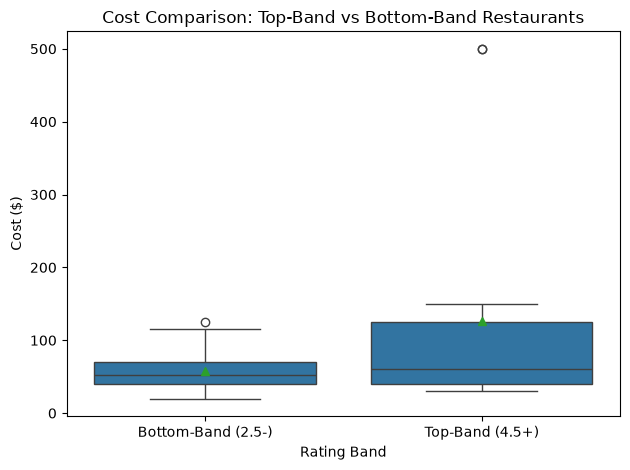

In [12]:
# Q3: Are top-band restaurants (4.5+, 15 records) more expensive than bottom-band ones (below 2.5, 60 records)?
top_band = df[df['rating_number_historical'] >= 4.5]
bottom_band = df[df['rating_number_historical'] < 2.5]
print(f"Top band count: {len(top_band)}, mean cost: {top_band['cost'].mean():.2f}")
print(f"Bottom band count: {len(bottom_band)}, mean cost: {bottom_band['cost'].mean():.2f}")

plt.figure()
comparison_df = df.copy()
comparison_df['Band'] = 'Other'
comparison_df.loc[comparison_df['rating_number_historical'] >= 4.5, 'Band'] = 'Top-Band (4.5+)'
comparison_df.loc[comparison_df['rating_number_historical'] < 2.5, 'Band'] = 'Bottom-Band (2.5-)'
subset_band = comparison_df[comparison_df['Band'] != 'Other']
sns.boxplot(x='Band', y='cost', data=subset_band, showmeans=True)
plt.title("Cost Comparison: Top-Band vs Bottom-Band Restaurants")
plt.xlabel("Rating Band")
plt.ylabel("Cost ($)")
plt.tight_layout()
plt.show()

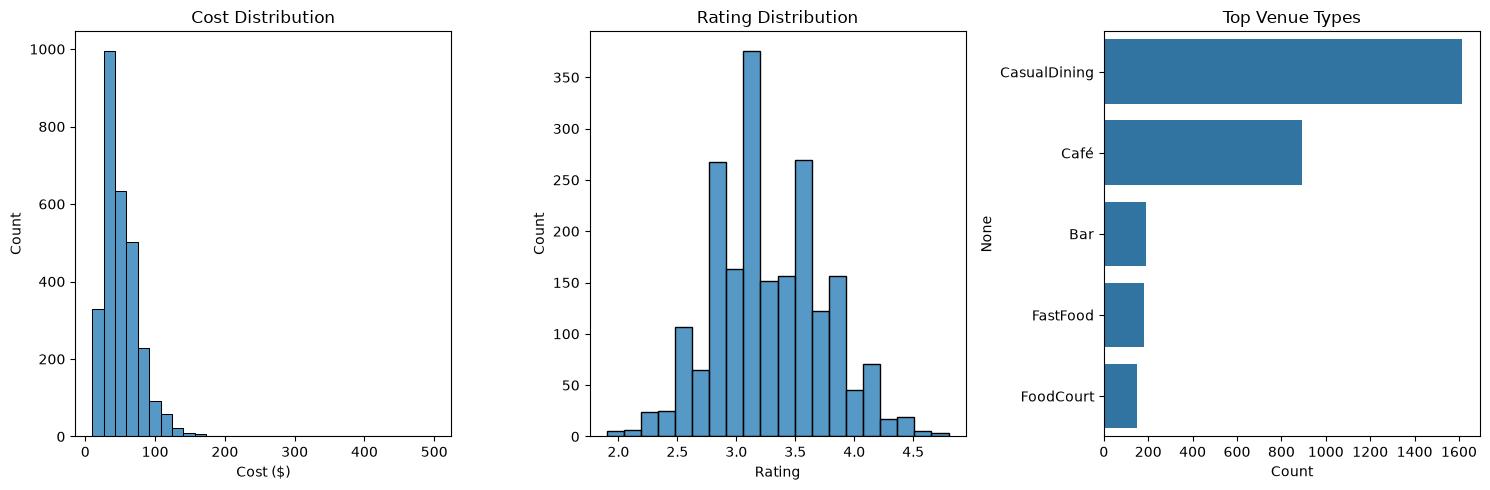

In [13]:
# Q4: What do the distributions of cost, rating and venue type look like?
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
sns.histplot(df['cost'].dropna(), bins=30, ax=axes[0])
axes[0].set_title("Cost Distribution")
axes[0].set_xlabel("Cost ($)")

sns.histplot(df['rating_number_historical'].dropna(), bins=20, ax=axes[1])
axes[1].set_title("Rating Distribution")
axes[1].set_xlabel("Rating")


types_list = []
for t_str in df['type'].dropna():
    t_str_list = t_str.split(',')
    types_list.extend(t_str_list)

top_types = pd.Series(types_list).value_counts().head(5)
sns.barplot(x=top_types.values, y=top_types.index, ax=axes[2])
axes[2].set_title("Top Venue Types")
axes[2].set_xlabel("Count")

plt.tight_layout()
plt.show()

Correlation between cost and cuisine count: 0.050


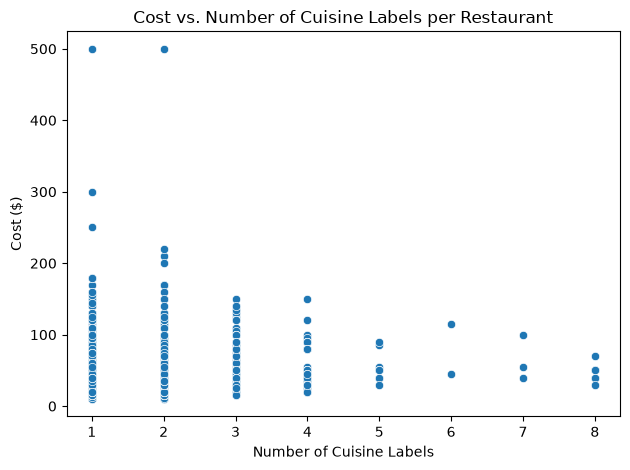

In [14]:
# Q5: Is cost related to the number of cuisine labels?
df['cuisine_count'] = df['cuisine'].apply(lambda x: len(x.split(',')))
corr = df['cost'].corr(df['cuisine_count'])
print(f"Correlation between cost and cuisine count: {corr:.3f}")

plt.figure()
sns.scatterplot(x='cuisine_count', y='cost', data=df)
plt.title("Cost vs. Number of Cuisine Labels per Restaurant")
plt.xlabel("Number of Cuisine Labels")
plt.ylabel("Cost ($)")
plt.tight_layout()
plt.show()

Cafes count: 891, Fine dining count: 30


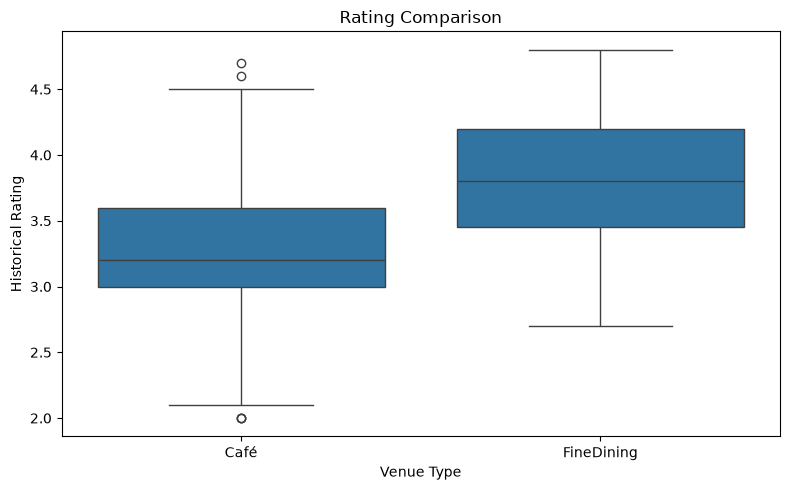

In [15]:
# Q6: Do cafés and fine-dining venues differ in rating?
def has_type(type_str, target):
    """Parse literal string to list then check if target is in the list"""
    return parsed == target


cafes = df['type'].str.contains('Café')
fine_dining = df['type'].str.contains('FineDining')

print(f"Cafes count: {cafes.sum()}, Fine dining count: {fine_dining.sum()}")

cafe_fine_df = pd.concat([
    df[cafes].assign(Venue_Type='Café'),
    df[fine_dining].assign(Venue_Type='FineDining')
])

plt.figure(figsize=(8, 5))
sns.boxplot(x='Venue_Type', y='rating_number_historical', data=cafe_fine_df)
plt.title("Rating Comparison")
plt.xlabel("Venue Type")
plt.ylabel("Historical Rating")
plt.tight_layout()
plt.show()

Matched restaurants: 2612
Unmatched restaurants (with coordinates): 291
Without coordinates: 97
Total: 3000
Total 'Italian' restaurants matched: 195


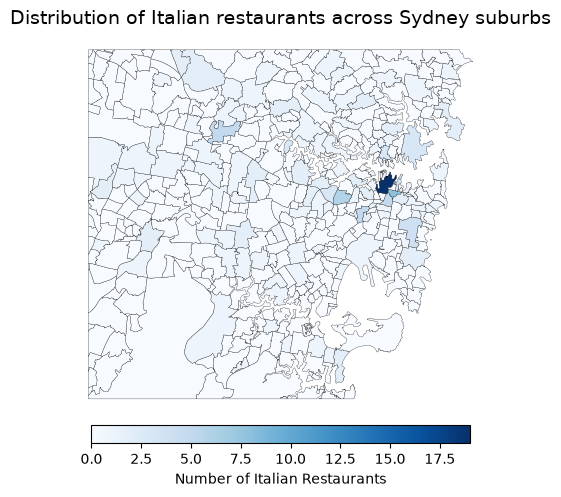

In [38]:
# A3: With GeoPandas, match each restaurant to a suburb by its coordinates, not by the subzone text. 
# Make sure both layers use the same coordinate system, and drop the 23 suburbs with no shape. 
# Choose one cuisine, and colour each suburb by the number of your restaurants serving it. 
# Report how many restaurants were matched, unmatched and without coordinates.

# matching already did in A2, with the same coord system - crs = geo_syd.crs
# geo_syd = geo_syd[~geo_syd['geometry'].isna()] - drop
# geo_restaurants = gpd.GeoDataFrame(df_valid, geometry=geometry, crs=geo_syd.crs): 
# joined = gpd.sjoin(geo_restaurants, geo_syd, how="left", predicate="intersects")
# inside_map = joined[~joined['index_right'].isna()]
# outside_map = joined[joined['index_right'].isna()]
df_no_coords = df[df['lat'].isna() | df['lng'].isna()]

print(f"Matched restaurants: {len(inside_map)}")
print(f"Unmatched restaurants (with coordinates): {len(outside_map)}")
print(f"Without coordinates: {len(df_no_coords)}")
print(f"Total: {len(inside_map) + len(outside_map) + len(df_no_coords)}")

# Choose one cuisine: Italian
chosen_cuisine = 'Italian'

inside_map['is_chosen_cuisine'] = inside_map['cuisine'].str.contains(chosen_cuisine)

# Aggregate by suburb - SSC_NAME
suburb_chosen_cuisine_counts = inside_map[inside_map['is_chosen_cuisine']].\
    groupby('SSC_NAME').size().reset_index(name='chosen_cuisine_count')
print(f"Total '{chosen_cuisine}' restaurants matched: {suburb_chosen_cuisine_counts['chosen_cuisine_count'].sum()}")

# Merge back to geo map of SYD
geo_with_chosen_cuisine = geo_syd.merge(suburb_chosen_cuisine_counts, on='SSC_NAME', how='left')
geo_with_chosen_cuisine['chosen_cuisine_count'] = geo_with_chosen_cuisine['chosen_cuisine_count'].fillna(0)

fig, ax = plt.subplots(1, 1, figsize=(5,5))
geo_with_chosen_cuisine.plot(column='chosen_cuisine_count', ax=ax, legend=True,
                            legend_kwds={
                                'label': f"Number of {chosen_cuisine} Restaurants",
                                'orientation': "horizontal",
                                'pad': 0.02,
                                'fraction': 0.046
                                },
                            cmap='Blues', edgecolor='black', linewidth=0.2)
ax.set_title(f"Distribution of {chosen_cuisine} restaurants across Sydney suburbs", fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.show()

In [17]:
# A4: Turn one of your A2 findings into an interactive chart with Plotly or Bokeh. 
# Users must be able to hover, filter or zoom. 
# Save it as an HTML file, and explain what the interaction shows that a static plot cannot.

import plotly.express as px

# convert Q5 (Cost vs. Number of Cuisine Labels) into an interactive Plotly boxplot.

# create an interactive box plot using plotly
fig = px.box(
    df,
    x='cuisine_count',
    y='cost',
    color='cuisine_count',
    points="all", # Shows all points alongside the box
    hover_data=['title', 'subzone', 'rating_number_historical'], # data shown when hovering
    title="Cost vs. Number of Cuisine Labels per Restaurant - Plotly",
    labels={
        'cuisine_count': 'Number of Cuisine Labels',
        'cost': 'Cost (AUD)',
        'title': 'Restaurant',
        'subzone': 'Subzone',
        'rating_number_historical': 'Rating'
    }
)

fig.update_layout(showlegend=False) # Hide unnecessary legend

# Save as an interactive HTML file
q5_plot_filename = "interactive_q5_cost_vs_cuisine.html"
fig.write_html("../outputs/" + q5_plot_filename)
print(f"Saved interactive chart to {q5_plot_filename}")

Saved interactive chart to interactive_q5_cost_vs_cuisine.html


In [33]:
# A5 
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor

df_with_rating = df.dropna(subset=['rating_number_historical'])

# Create the binary labels for stratification and classification (1 = >= 3.5, 0 = < 3.5)
df_with_rating['class_label'] = (df_with_rating['rating_number_historical'] >= 3.5).astype(int)

# Define the permitted input features
# cuisine_count created before  
X_cols = ['cost', 'cuisine', 'type', 'subzone', 'cuisine_count'] 
numeric_features = ['cost', 'cuisine_count'] 
categorical_features = ['cuisine', 'type', 'subzone']

# Exclude the target, its derivatives, and identifiers from inputs
X = df_with_rating[X_cols]
y_clf = df_with_rating['class_label']
y_reg = df_with_rating['rating_number_historical']
record_ids = df_with_rating['record_id']

# Make 80/20 train/test split, stratified by class label.
# Pass both record_ids and y targets through the split to get the train and test idx
X_train, X_test, y_train_cls, y_test_cls, y_train_reg, y_test_reg, ids_train, ids_test = train_test_split(
    X, 
    y_clf, 
    y_reg,
    record_ids,
    test_size=0.2, 
    random_state=MODEL_SEED, 
    stratify=y_clf  # Stratify using the classification label
)

# Save the record_ids for the exact splits so they can be reused identically
ids_train.to_csv('../outputs/train_record_ids.csv', index=False)
ids_test.to_csv('../outputs/test_record_ids.csv', index=False)

# Put all preprocessing (filling gaps, encoding, scaling) inside scikit-learn pipelines.
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), # Fill gaps in numeric features
    ('scaler', StandardScaler())     # Scale numeric features
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='missing')), # Fill gaps in categorical data
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

# Create the full modeling pipeline (Preprocessing + Model)
reg_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestRegressor(random_state=MODEL_SEED))
])

# Tune with cross-validation strictly on the training data.
param_grid = {
    'classifier__n_estimators': [50, 100],
    'classifier__max_depth': [None, 10]
}

grid_search = GridSearchCV(reg_pipe, param_grid, cv=5, scoring='neg_mean_squared_error')

# Fit the grid search
grid_search.fit(X_train, y_train_reg)

print(f"Best CV accuracy on training data: {-grid_search.best_score_:.4f}")
print(f"Best parameters found: {grid_search.best_params_}")

Best CV accuracy on training data: 0.2004
Best parameters found: {'classifier__max_depth': 10, 'classifier__n_estimators': 100}


In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_validate


rf = RandomForestRegressor(max_depth=10, n_estimators=100, random_state=MODEL_SEED)
dt = DecisionTreeRegressor(random_state=MODEL_SEED)
lr = LinearRegression()
gb = GradientBoostingRegressor(random_state=MODEL_SEED)
base = DummyRegressor()

models = {
    "baseline": base,
    "rf": rf,
    "dt": dt,
    "lr": lr,
    "grboost": gb
}

scoring_metrics = {
    'mse': 'neg_mean_squared_error',    # sklearn defaults maximising, so - for error to minimise error
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}
for name, model in models.items():
    # Create the full modeling pipeline (Preprocessing + Model)
    reg_pipe_each = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    score = cross_validate(reg_pipe_each, X_train, y_train_reg, cv=5, scoring=scoring_metrics)
    print(f"name: {name}")
    print(f"MSE: {-score['test_mse'].mean():.4f} +- {score['test_mse'].std():.4f}")
    print(f"RMSE: {-score['test_rmse'].mean():.4f} +- {score['test_rmse'].std():.4f}")
    print(f"R2: {score['test_r2'].mean():.4f} +- {score['test_r2'].std():.4f}\n")
    

name: baseline
MSE: 0.2188 +- 0.0198
RMSE: 0.4673 +- 0.0209
R2: -0.0031 +- 0.0029

name: rf
MSE: 0.2004 +- 0.0197
RMSE: 0.4471 +- 0.0220
R2: 0.0811 +- 0.0465

name: dt
MSE: 0.3239 +- 0.0311
RMSE: 0.5684 +- 0.0270
R2: -0.4847 +- 0.0556

name: lr
MSE: 0.2792 +- 0.0232
RMSE: 0.5279 +- 0.0218
R2: -0.2831 +- 0.0869

name: grboost
MSE: 0.1996 +- 0.0190
RMSE: 0.4463 +- 0.0212
R2: 0.0844 +- 0.0458



In [20]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [21]:
import numpy as np
from sklearn.metrics import mean_squared_error, root_mean_squared_error, r2_score

# Gradient Descent method
def batch_gd(X, y, lr=0.1, epochs=500):
    m, n = X.shape
    X_b = np.c_[np.ones((m, 1)), X]    # adding the bias term, c_ = concat
    theta = np.zeros(n + 1)   # init weights
    losses = []
    
    for _ in range(epochs):
        predictions = X_b.dot(theta)   # forward pass (X.theta)
        error = predictions - y    # residual vector   (X.theta - Y)
        loss = (1/m) * np.sum(error**2)   # MSE loss
        losses.append(loss)   
        # computes the partial derivatives of the cost function with respect to each individual weight
        gradients = (2/m) * X_b.T.dot(error)    # partial derivate 2/m XT.(X.theta - Y)
        theta -= lr * gradients  # weight update
        
    return theta, losses

theta_gd, losses_gd = batch_gd(X_train_processed, y_train_reg)

X_test_b = np.c_[np.ones((X_test_processed.shape[0], 1)), X_test_processed]
y_pred_gd = X_test_b.dot(theta_gd)
gd_mse = mean_squared_error(y_test_reg, y_pred_gd)
gd_rmse = root_mean_squared_error(y_test_reg, y_pred_gd)
gd_r2 = r2_score(y_test_reg, y_pred_gd)

In [22]:
print(f'MSE of GD: {gd_mse:.4f}')
print(f'RMSE of GD: {gd_rmse:.4f}')
print(f'R2 of GD: {gd_r2:.4f}')
# choose GD

MSE of GD: 0.1739
RMSE of GD: 0.4170
R2 of GD: 0.1012


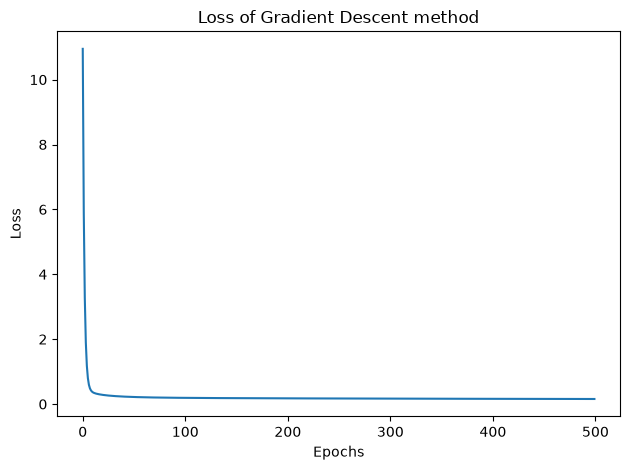

In [23]:
# Plot GD losses
plt.plot(losses_gd)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss of Gradient Descent method")
plt.tight_layout()
plt.show()

In [24]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier


rf_clf = RandomForestClassifier(max_depth=10, n_estimators=100, random_state=MODEL_SEED)
lr_clf = LogisticRegression()
gb_clf = GradientBoostingClassifier(random_state=MODEL_SEED)
base_clf = DummyClassifier(strategy="most_frequent")

models_clf = {
    "baseline": base_clf,
    "rf": rf_clf,
    "lr": lr_clf,
    "grboost": gb_clf
}


scoring_metrics_clf = {
    'acc': 'accuracy',
    'pre': 'precision',
    'rec': 'recall',
    'f1': 'f1',
    'f1_macro': 'f1_macro',
}

for name, model in models_clf.items():
    # Create the full modeling pipeline (Preprocessing + Model)
    reg_pipe_each = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])
    score = cross_validate(reg_pipe_each, X_train, y_train_cls, cv=5, scoring=scoring_metrics_clf)
    print(f"name: {name}")
    print(f"Accuracy: {score['test_acc'].mean():.4f} +- {score['test_acc'].std():.4f}")
    print(f"Precision: {score['test_pre'].mean():.4f} +- {score['test_pre'].std():.4f}")
    print(f"Recall: {score['test_rec'].mean():.4f} +- {score['test_rec'].std():.4f}")
    print(f"F1: {score['test_f1'].mean():.4f} +- {score['test_f1'].std():.4f}")
    print(f"F1 Macro: {score['test_f1_macro'].mean():.4f} +- {score['test_f1_macro'].std():.4f}\n")
    # choose lr

c:\Users\Huy\miniconda3\envs\dsts\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Huy\miniconda3\envs\dsts\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Huy\miniconda3\envs\dsts\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Huy\miniconda3\e

name: baseline
Accuracy: 0.6559 +- 0.0005
Precision: 0.0000 +- 0.0000
Recall: 0.0000 +- 0.0000
F1: 0.0000 +- 0.0000
F1 Macro: 0.3961 +- 0.0002

name: rf
Accuracy: 0.6614 +- 0.0015
Precision: 0.9333 +- 0.1333
Recall: 0.0177 +- 0.0000
F1: 0.0347 +- 0.0001
F1 Macro: 0.4147 +- 0.0006

name: lr
Accuracy: 0.6602 +- 0.0218
Precision: 0.5153 +- 0.0539
Recall: 0.2991 +- 0.0189
F1: 0.3775 +- 0.0243
F1 Macro: 0.5718 +- 0.0196

name: grboost
Accuracy: 0.6577 +- 0.0195
Precision: 0.5187 +- 0.0789
Recall: 0.1752 +- 0.0180
F1: 0.2606 +- 0.0254
F1 Macro: 0.5189 +- 0.0182



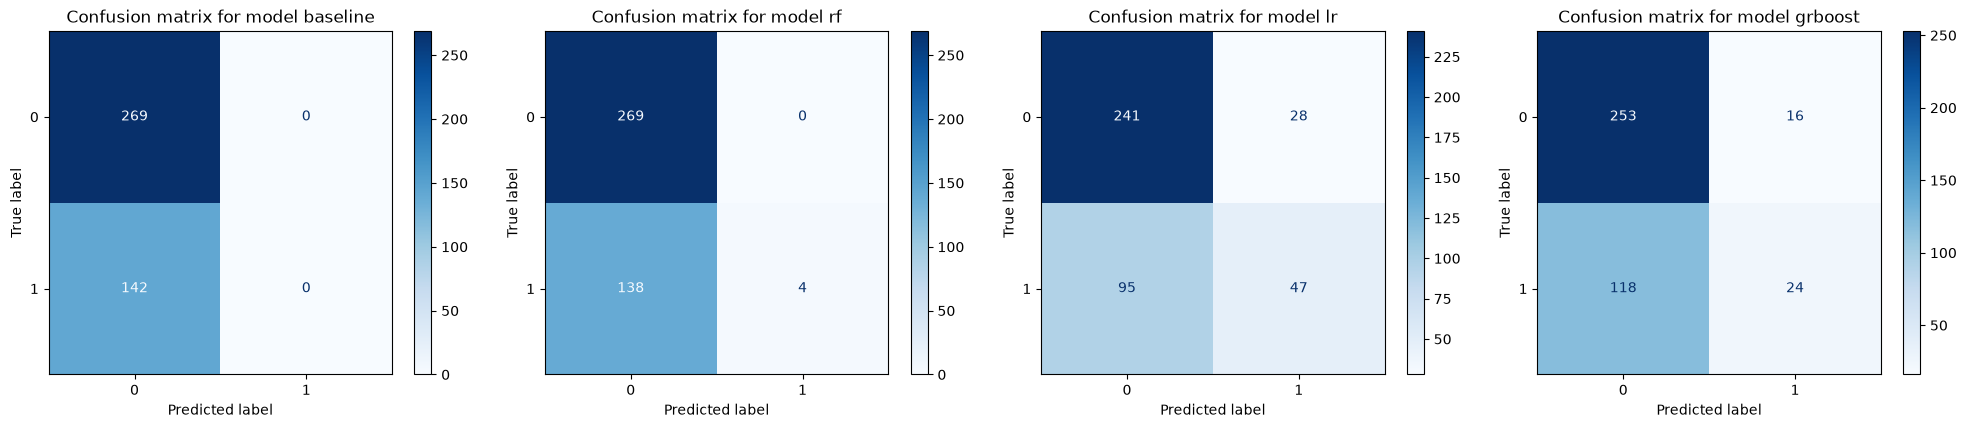

In [25]:
# confusion matrix
num_models = len(models_clf)
fig, axes = plt.subplots(nrows=1, ncols=num_models, figsize=(5 * num_models, 4))

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
for i, (name, model) in enumerate(models_clf.items()):
    model.fit(X_train_processed, y_train_cls)
    y_pred_cls = model.predict(X_test_processed)
    cm = confusion_matrix(y_test_cls, y_pred_cls)
    ax_current = axes[i]
    cm_plot = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    cm_plot.plot(ax=ax_current, cmap="Blues")
    ax_current.set_title(f"Confusion matrix for model {name}")

plt.tight_layout()
plt.show() 


Number of components explaining 90% variance: 231


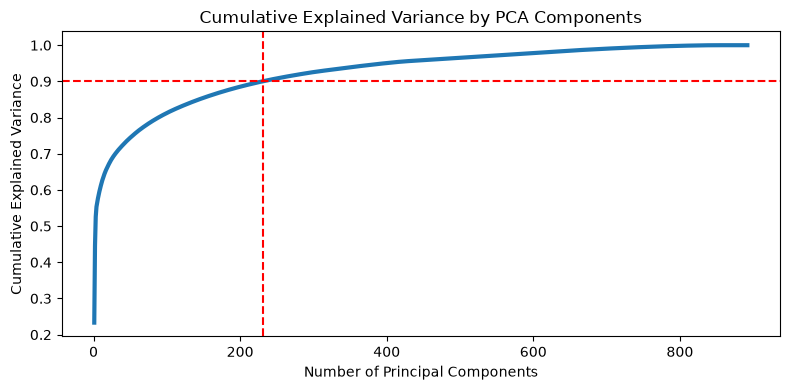

In [26]:
# A8: PCA
from sklearn.decomposition import PCA
X_train_processed = preprocessor.fit_transform(X_train) # preprocessor include scaling

pca_full = PCA(random_state=MODEL_SEED)
pca_full.fit(X_train_processed)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)     # cumulative variance
n_components_90 = np.argmax(cum_var >= 0.90) + 1      # get the 
print(f"Number of components explaining 90% variance: {n_components_90}")

# Explained variance with 90% threshold
plt.figure(figsize=(8,4))
plt.plot(range(1, len(cum_var)+1), cum_var, linewidth=3.0)
plt.axhline(y=0.90, color='r', linestyle='--')
plt.axvline(x=n_components_90, color='r', linestyle='--')
plt.title('Cumulative Explained Variance by PCA Components')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.tight_layout()
plt.show()

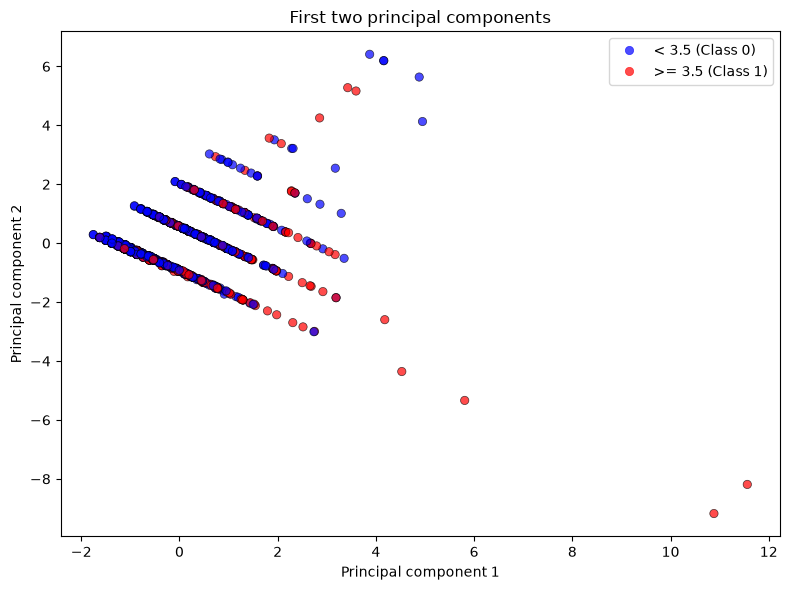

In [27]:
# PC1 vs PC2 component
pca_2 = PCA(n_components=2, random_state=MODEL_SEED)
X_pca_2 = pca_2.fit_transform(X_train_processed)

plt.figure(figsize=(8,6))
scatter = plt.scatter(X_pca_2[:, 0], X_pca_2[:, 1], c=y_train_cls,
                      cmap='bwr', alpha=0.7, edgecolors='k', linewidth=0.5)
plt.xlabel(f'Principal component 1')
plt.ylabel(f'Principal component 2')
plt.title('First two principal components')
plt.legend(handles=scatter.legend_elements()[0],
           labels=['< 3.5 (Class 0)', '>= 3.5 (Class 1)'])
plt.tight_layout()
plt.show()

In [28]:
# Compare CV for Logistic Regression classifier
pipe_no_pca = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(random_state=MODEL_SEED))
])

pipe_pca = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('pca', PCA(n_components=0.90, random_state=MODEL_SEED)),
    ('classifier', LogisticRegression(random_state=MODEL_SEED))
])

cv_no_pca = cross_validate(pipe_no_pca, X_train, y_train_cls, cv=5, scoring='f1_macro')
cv_pca = cross_validate(pipe_pca, X_train, y_train_cls, cv=5, scoring='f1_macro')

print(f"CV F1 macro score without PCA: {cv_no_pca['test_score'].mean():.4f} +- {cv_no_pca['test_score'].std():.4f}")
print(f"CV F1 macro score with 90% PCA: {cv_pca['test_score'].mean():.4f} +- {cv_pca['test_score'].std():.4f}")

CV F1 macro score without PCA: 0.5718 +- 0.0196
CV F1 macro score with 90% PCA: 0.5686 +- 0.0340


In [29]:
# A9: Permutation Importance on Test Set
from sklearn.inspection import permutation_importance

model = LogisticRegression(random_state=MODEL_SEED)
model.fit(X_train_processed, y_train_cls)
perm_imp = permutation_importance(model, X_test_processed, y_test_cls, 
                                  n_repeats=10, random_state=MODEL_SEED, scoring='f1_macro')
perm_mean = perm_imp.importances_mean
perm_std = perm_imp.importances_std
feature_names = preprocessor.get_feature_names_out()
clean_feature_names = [f.replace('num__', '').replace('cat__', '') for f in feature_names]

sorted_perm_idx = perm_mean.argsort()[::-1]  # descending

print("Top 5 Permutation Importances (Test Set):")
top_perm_names = []
top_perm_vals = []
top_perm_stds = []
for idx in sorted_perm_idx[:5]:
    name = clean_feature_names[idx]
    mean_v = perm_mean[idx]
    std_v = perm_std[idx]
    top_perm_names.append(name)
    top_perm_vals.append(mean_v)
    top_perm_stds.append(std_v)
    print(f"{name}: {mean_v:.4f} +- {std_v:.4f}")


Top 5 Permutation Importances (Test Set):
cost: 0.0684 +- 0.0118
type_CasualDining: 0.0190 +- 0.0083
type_CasualDining,WineBar: 0.0127 +- 0.0054
subzone_Darlinghurst: 0.0120 +- 0.0035
subzone_Randwick: 0.0101 +- 0.0037


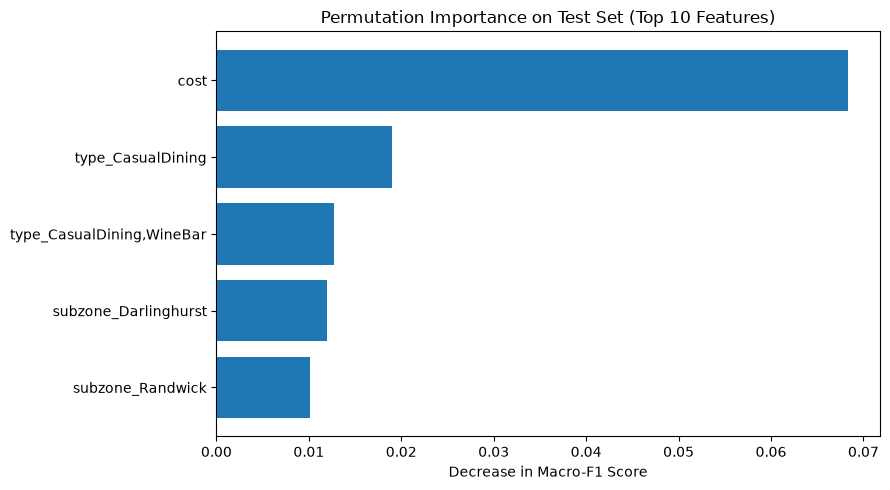

In [30]:
# Plot Permutation Importance
plt.figure(figsize=(9, 5))
plt.barh(top_perm_names, top_perm_vals)
plt.gca().invert_yaxis()
plt.xlabel("Decrease in Macro-F1 Score")
plt.title("Permutation Importance on Test Set (Top 10 Features)")
plt.tight_layout()
plt.show()

c:\Users\Huy\miniconda3\envs\dsts\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


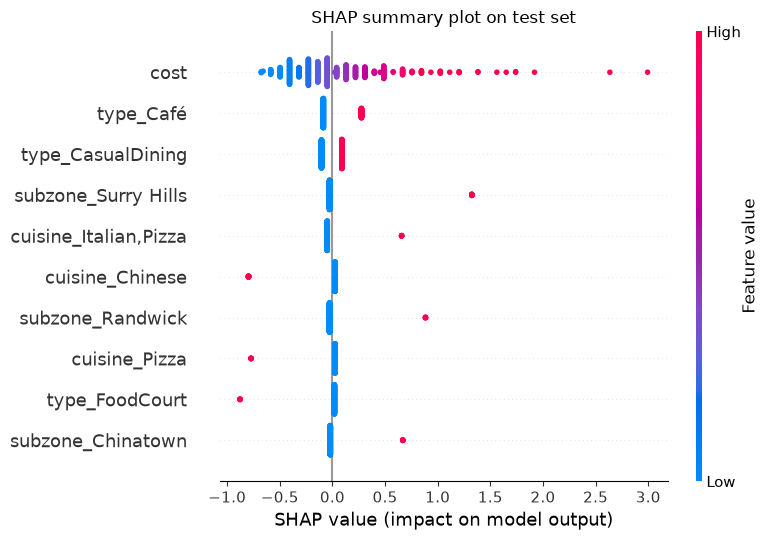

In [31]:
import shap
# initialise LinearExplainer using training distribution
explainer = shap.LinearExplainer(model, X_train_processed)

# Compute SHAP values for the unseen test set
shap_values = explainer(X_test_processed)

# Generate SHAP plot (global importance)
plt.figure(figsize=(5, 3))
shap.summary_plot(
    shap_values, 
    X_test_processed, 
    feature_names=clean_feature_names, 
    max_display=10,
    show=False
)
plt.title("SHAP summary plot on test set")
plt.tight_layout()
plt.show()

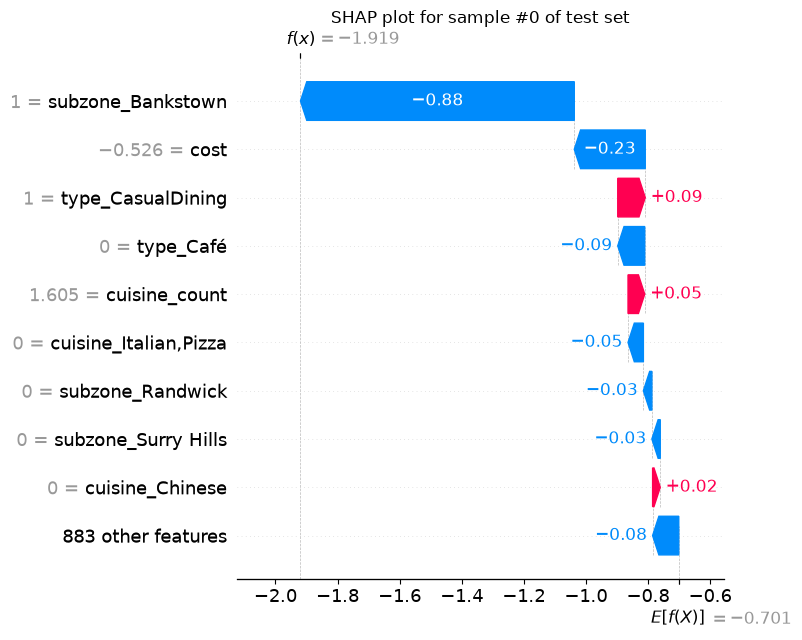

In [32]:
# A9 single instance explanation
sample_idx = 0

# create SHAP explanation object for sample #0
single_explanation = shap.Explanation(
    values=shap_values.values[sample_idx],
    base_values=shap_values.base_values[sample_idx],
    data=X_test_processed[sample_idx],
    feature_names=clean_feature_names
)

plt.figure(figsize=(9, 5))
shap.plots.waterfall(single_explanation, max_display=10, show=False)
plt.title(f"SHAP plot for sample #{sample_idx} of test set")
plt.tight_layout()
plt.show()